# Project 1 – Pass-07


## Problem Definition



Business problem: Predict whether a customer will make a successfull transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

### File Paths

In [2]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

### Load data

In [3]:
#load data
transaction_df= pd.read_csv(url)

### Head

In [4]:
# first few rows
transaction_df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Tail

In [5]:
# last few rows
transaction_df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049999,1049999,train_1049999,0.0,2.1828,12.3805,17.5654,NaN,8.1795,NaN,NaN,...,NaN,-12.1108,NaN,10.7608,NaN,NaN,NaN,NaN,NaN,14.1690


### Shape

In [6]:
# shape of data frame
transaction_df.shape

#output (# of rows, # of columns)

(1050000, 104)

### Size

In [7]:
# size of data frame
transaction_df.size

109200000

### Info

In [8]:
# display meta-data
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050000 entries, 0 to 1049999
Columns: 104 entries, Unnamed: 0 to var_100
dtypes: float64(102), int64(1), object(1)
memory usage: 833.1+ MB


## Summary statistics

### Describe

In [9]:
# display summary statistics
transaction_df.describe()


,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
count,1.050000e+06,180000.000000,180000.000000,180000.000000,180000.000000,0.0,180000.000000,0.0,0.0,180000.000000,...,0.0,180000.000000,0.0,180000.000000,0.0,0.0,0.0,0.0,0.0,180000.000000
mean,5.249995e+05,0.100222,7.440715,15.870166,12.735619,NaN,-0.668334,NaN,NaN,1.190419,...,NaN,-3.294620,NaN,-6.727860,NaN,NaN,NaN,NaN,NaN,14.224538
std,3.031090e+05,0.300297,3.021636,3.010492,4.185923,NaN,5.968300,NaN,NaN,5.169343,...,NaN,7.418545,NaN,8.278554,NaN,NaN,NaN,NaN,NaN,0.171058
min,0.000000e+00,0.000000,-2.691700,6.299300,-1.018500,NaN,-22.748700,NaN,NaN,-15.194000,...,NaN,-29.984000,NaN,-35.211700,NaN,NaN,NaN,NaN,NaN,13.729000
25%,2.624998e+05,0.000000,5.160325,13.830400,9.664675,NaN,-4.997500,NaN,NaN,-2.571400,...,NaN,-8.757925,NaN,-12.835875,NaN,NaN,NaN,NaN,NaN,14.098900
50%,5.249995e+05,0.000000,7.350950,15.934600,12.670700,NaN,-0.560300,NaN,NaN,1.194600,...,NaN,-3.170950,NaN,-6.615100,NaN,NaN,NaN,NaN,NaN,14.226800
75%,7.874992e+05,0.000000,9.511125,18.061425,15.837300,NaN,3.632525,NaN,NaN,5.090450,...,NaN,2.043350,NaN,-0.885250,NaN,NaN,NaN,NaN,NaN,14.361800
max,1.049999e+06,1.000000,16.716500,26.079100,26.997600,NaN,18.855400,NaN,NaN,18.471400,...,NaN,21.236400,NaN,18.105600,NaN,NaN,NaN,NaN,NaN,14.743000


### Target value counts

NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [10]:
# value_counts on target ; include nulls
transaction_df['target'].value_counts(dropna=False)

,count
target,
NaN,870000
0.0,161960
1.0,18040


In [11]:
#normalize value counts on target ; include nulls
transaction_df['target'].value_counts(normalize=True, dropna=False)

,proportion
target,
NaN,0.828571
0.0,0.154248
1.0,0.017181


### Nulls

In [12]:
# look for nulls
transaction_df.isnull().sum().sort_values(ascending=False)

#output

,0
var_3,1050000
var_16,1050000
var_12,1050000
var_11,1050000
var_9,1050000
...,...
var_88,870000
var_94,870000
var_100,870000
Unnamed: 0,0


### Column data types

In [13]:
# display data types
transaction_df.dtypes.sort_values()

,0
Unnamed: 0,int64
var_72,float64
var_71,float64
var_70,float64
var_69,float64
...,...
var_26,float64
var_25,float64
var_35,float64
var_100,float64


###Unique elements

In [14]:
# number of unique elements in every column (works on the whole dataframe)
transaction_df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,1050000
ID_code,1050000
var_52,137280
var_86,134537
var_94,131746
...,...
var_93,0
var_96,0
var_97,0
var_98,0


In [15]:
# actual unique values in one column
transaction_df['target'].unique()

array([nan,  0.,  1.])

## Data Cleaning



Backup #1

In [16]:
# backup copy of the original data
transaction_df_backup= transaction_df.copy()


In [17]:
# restore from backup
transaction_df=transaction_df_backup.copy()

### Keep only the target and features

Selected `target` for the target and `var_0 through var_19` for the features

In [18]:
# select the target (first 1000 rows)
transaction_df_target=transaction_df[['target']].head(1000).copy()
transaction_df_target.shape

(1000, 1)

In [19]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)
# check the list (show 50 names)
print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_14', 'var_15', 'var_16', 'var_17', 'var_18', 'var_19', 'var_20', 'var_21', 'var_22', 'var_23', 'var_24', 'var_25', 'var_26', 'var_27', 'var_28', 'var_29', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_36', 'var_37', 'var_38', 'var_39', 'var_40', 'var_41', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_48', 'var_49', 'var_50', 'var_51', 'var_52', 'var_53', 'var_54', 'var_55', 'var_56', 'var_57', 'var_58', 'var_59', 'var_60', 'var_61', 'var_62', 'var_63', 'var_64', 'var_65', 'var_66', 'var_67', 'var_68', 'var_69', 'var_70', 'var_71', 'var_72', 'var_73', 'var_74', 'var_75', 'var_76', 'var_77', 'var_78', 'var_79', 'var_80', 'var_81', 'var_82', 'var_83', 'var_84', 'var_85', 'var_86', 'var_87', 'var_88', 'var_89', 'var_90', 'var_91', 'var_92', 'var_93', 'var_94', 'var_95', 'var_96', 'var_97', 'var_98', 'var_99', 'var_100'

In [20]:
# select the target and the features
feature_cols= feature_cols[0:20] #keep only the first 20 features (var_0 to var_19)

#keep only the first 1000 rows,(.head(# of rows))
transaction_df_target_feature = transaction_df[['target'] + feature_cols].head(1000).copy()

transaction_df_target_feature.shape #verify


(1000, 21)

### Backup #2

In [ ]:
# make backup

In [ ]:
# restore from back up


### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns. (I kept only `target` and `var_0` to `var_4`.)

**2. Null values:** No feature column have nulls. no action needed

**3. Target nulls:** none, no rows dropped

**4. Feature columns with high null counts:** None

**5. Medium null counts:** none

**6. Low null counts:** none

**7. Null rows:** none


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

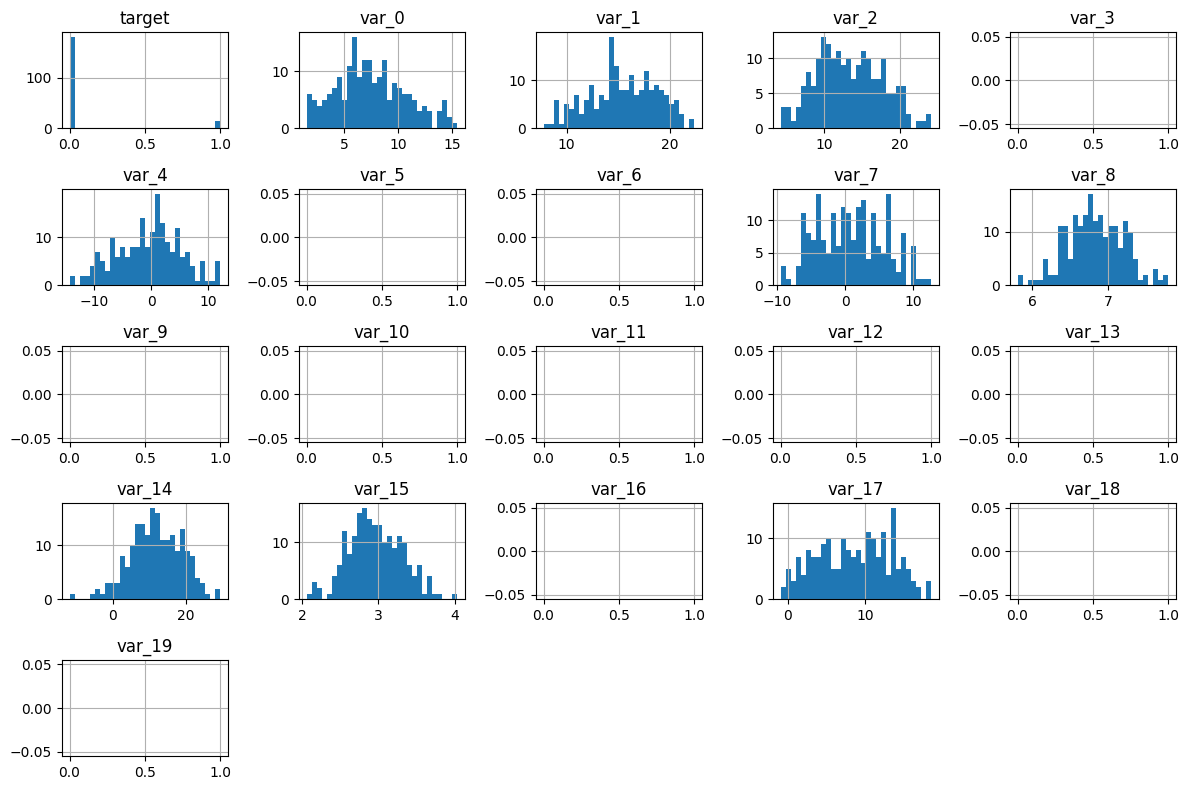

In [21]:
# Display a histogram - overview of target and the 5 features

transaction_df_target_feature.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


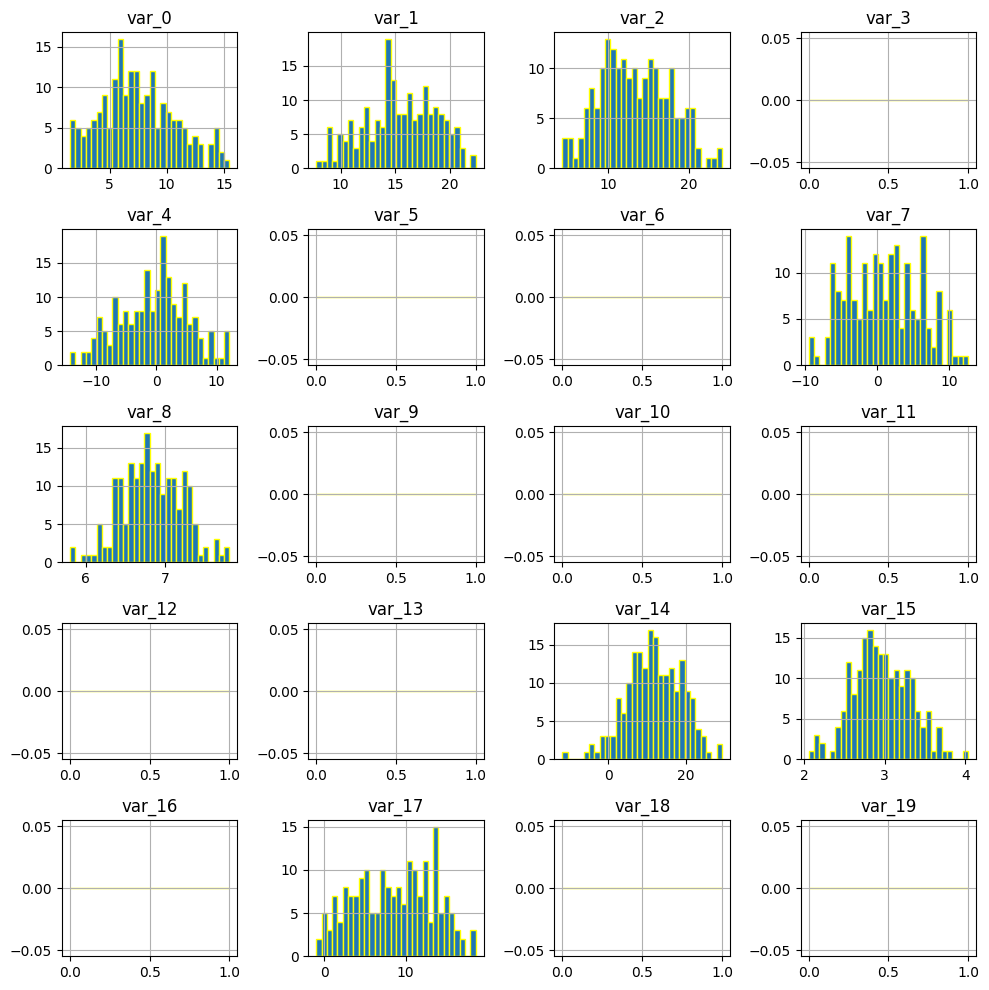

In [22]:
# Check the distributions of the 20 features (var_0 to var_19)

transaction_df_target_feature[feature_cols].hist(
  figsize=(10,10), # size of the whole picture in inches(width,height)
  layout=(5,4),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [23]:
# Calculate a correlation matrix (target & features)
transaction_df_target_feature.corr()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19
target,1.000000,-0.038213,-0.067624,-0.013390,NaN,0.011771,NaN,NaN,0.027500,-0.136106,...,NaN,NaN,NaN,NaN,0.029371,-0.031990,NaN,-0.036734,NaN,NaN
var_0,-0.038213,1.000000,0.056294,-0.105207,NaN,0.005331,NaN,NaN,0.121395,0.078862,...,NaN,NaN,NaN,NaN,-0.018901,0.012979,NaN,-0.082000,NaN,NaN
var_1,-0.067624,0.056294,1.000000,0.052516,NaN,-0.017052,NaN,NaN,0.010268,-0.055574,...,NaN,NaN,NaN,NaN,-0.010453,-0.055832,NaN,-0.105149,NaN,NaN
var_2,-0.013390,-0.105207,0.052516,1.000000,NaN,0.096484,NaN,NaN,0.004952,-0.061830,...,NaN,NaN,NaN,NaN,-0.034115,-0.093367,NaN,-0.061632,NaN,NaN
var_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_4,0.011771,0.005331,-0.017052,0.096484,NaN,1.000000,NaN,NaN,0.084078,-0.040961,...,NaN,NaN,NaN,NaN,-0.063154,-0.112470,NaN,-0.094116,NaN,NaN
var_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_7,0.027500,0.121395,0.010268,0.004952,NaN,0.084078,NaN,NaN,1.000000,0.031535,...,NaN,NaN,NaN,NaN,-0.087564,0.003846,NaN,0.014869,NaN,NaN
var_8,-0.136106,0.078862,-0.055574,-0.061830,NaN,-0.040961,NaN,NaN,0.031535,1.000000,...,NaN,NaN,NaN,NaN,-0.078755,-0.041556,NaN,0.070335,NaN,NaN


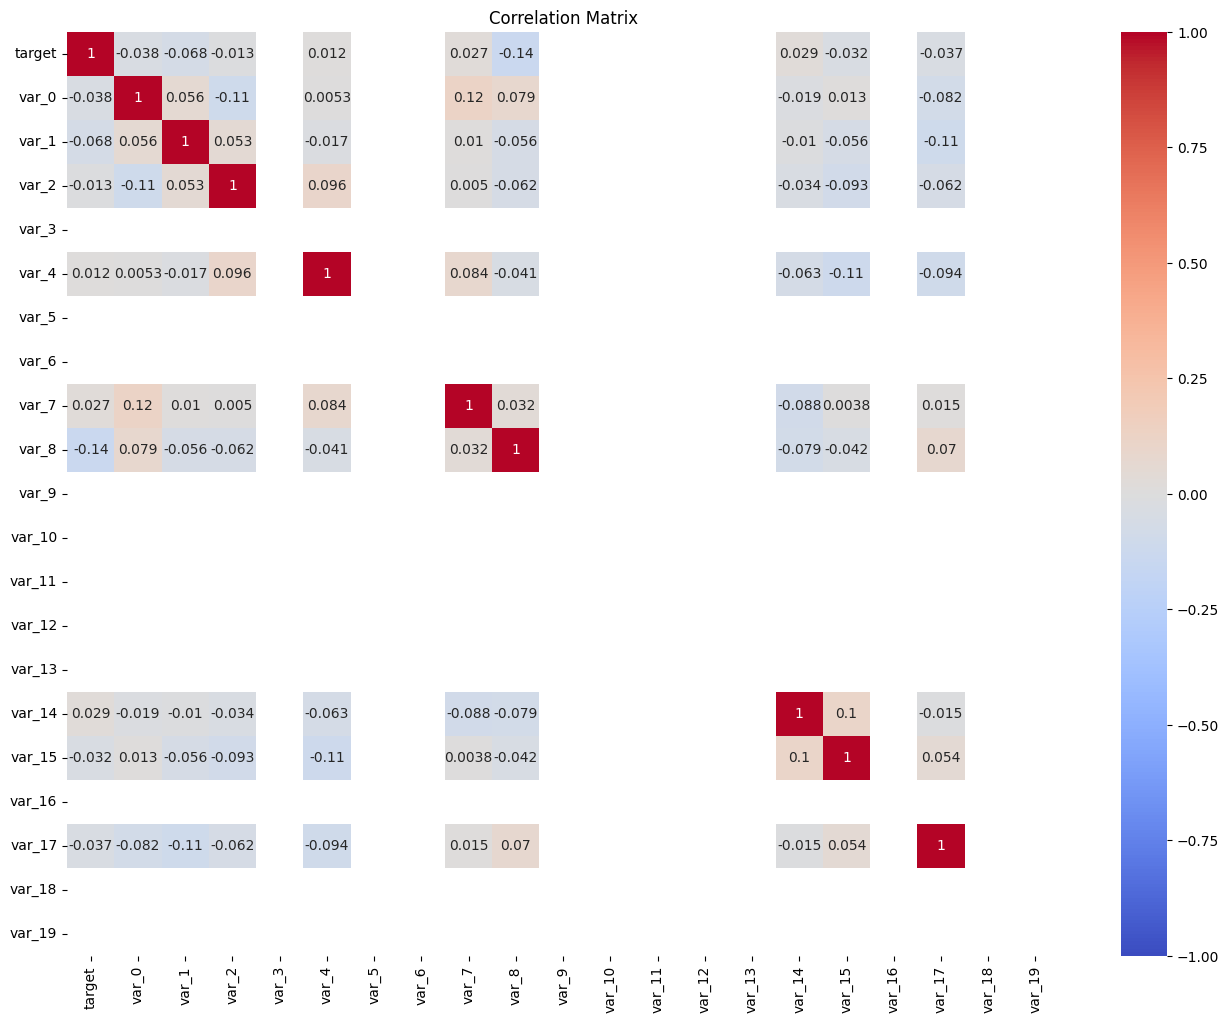

In [24]:
# Display the correlation matrix

plt.figure(figsize=(16, 12))
sns.heatmap(transaction_df_target_feature.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


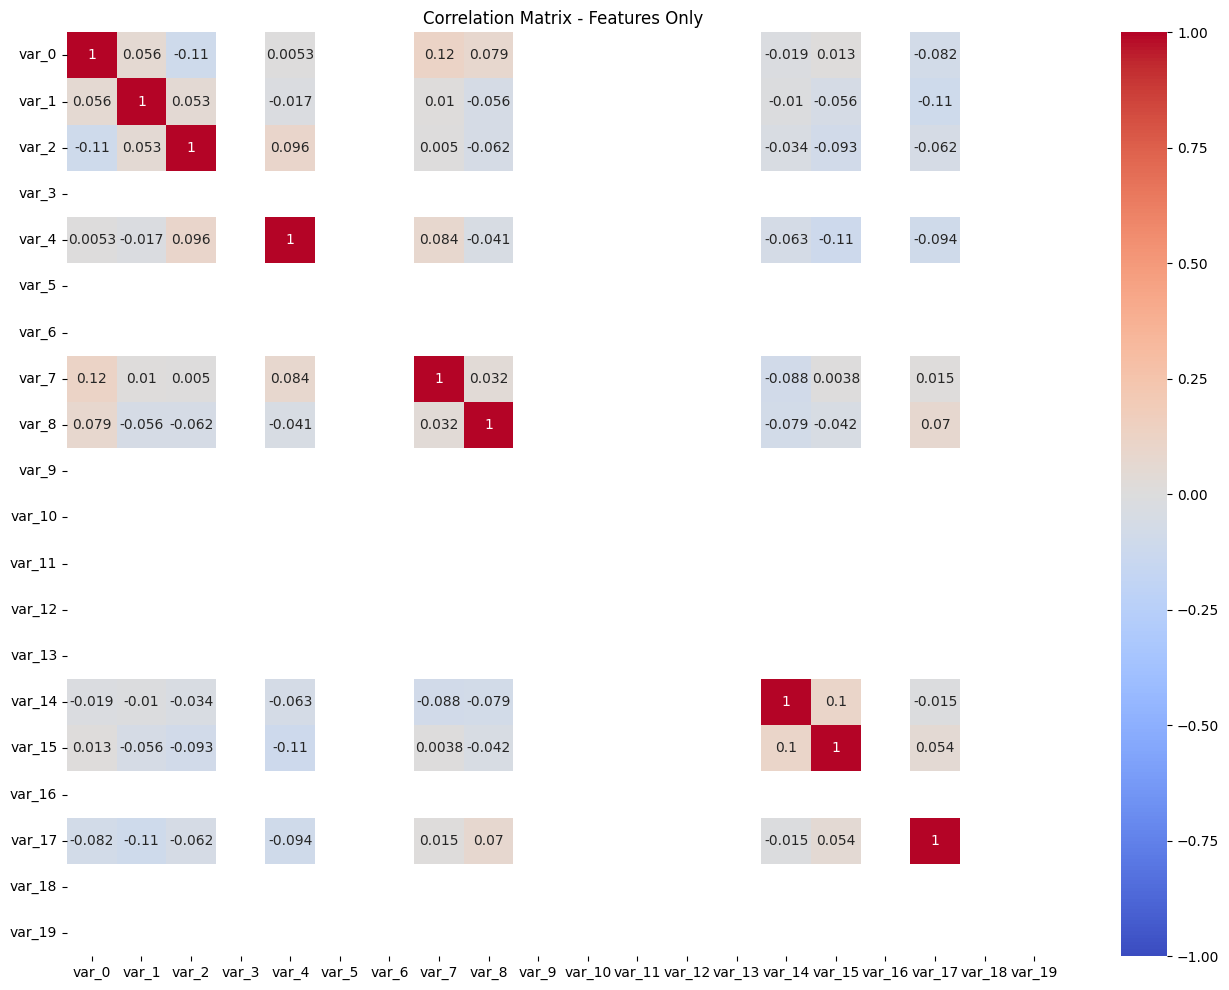

In [25]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_feature[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(feature_corr,
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [26]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_feature[transaction_df_target_feature['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_feature[transaction_df_target_feature['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(14, 21)
(180, 21)


## Data Processing

### Single Cross-validation

In [27]:
# Split data from into target and features
target =transaction_df_target['target'].copy()
features= transaction_df_target_feature [feature_cols].copy()



In [28]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [29]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(750, 20)
<class 'pandas.core.frame.DataFrame'>
(250, 20)
<class 'pandas.core.frame.DataFrame'>
(750,)
<class 'pandas.core.series.Series'>
(250,)
<class 'pandas.core.series.Series'>


### Model

In [30]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [31]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

ValueError: Input y contains NaN.

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))

#output show a warning message because model did not guess successful transactio
# zero_division=0 to remove the warning message


### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 90%


**Confusion matrix:**

 - 224: guessed no transaction, actually no transaction → right
  
 - 23: guessed no transaction, actually successfull transaction → wrong

 - 2: guessed sucessful transaction, actually no transaction -> wrong

 - 1: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.04
    - The model found 1 out 24 successfull transaction.

  - Precision for successfull transaction: 0.33
    - The model said successfull transaction 3 times, right once  

  - 90% is just for the no transaction customer.

**Takeaway:** The model guessed "no transaction" for most customer transaction.

